In [1]:
import numpy as np
import matplotlib.pyplot as pl
import pandas as pd
from glob import glob
import os, sys
from pathlib import Path
import tifffile as tf
from cmm import cmm
from importlib import reload
pl.style.use('dark_background')
sys.path.append('/groups/ahrens/home/ruttenv/code/zfish/')
from zfish.util import filesys as fs
from zfish.nir import cardio as ca
import zarr

In [2]:
base_dir = '/nrs/ahrens/Virginia_nrs/behavior_rig_flow/230304_f474_9dpf_casper/'
fnum = fs.get_fnum(base_dir)
print(f'fnum: {fnum}')

exp = 0
dirs_ = fs.get_subfolders(base_dir)
folder_path = dirs_[f'exp{exp}']
dirs = fs.get_subfolders(folder_path)

fnum: 474


In [3]:
impath = glob(dirs['imag_crop'] + '*.tif')[0]
im = tf.imread(impath)
dt, dx, dy = im.shape 
fs = 15.0
nperseg = int(fs*20)
noverlap = int(0.6*nperseg)
freq_minmax = [-np.inf, np.inf]
freq_minmax = [1,4]

In [4]:
xnt = im.reshape([dt, dx*dy]).T

In [5]:
reload(cmm)
opt_in_freqdom = True
k = 10
cm = cmm.CMM(
    xnt.astype('float32'),
    k=k,
    fs=fs,
    nperseg=nperseg,
    noverlap=noverlap,
    freq_minmax=freq_minmax,
    opt_in_freqdom=opt_in_freqdom,
)

2023-04-08 15:36:08.061834: E external/xla/xla/stream_executor/cuda/cuda_dnn.cc:429] Could not create cudnn handle: CUDNN_STATUS_INTERNAL_ERROR


XlaRuntimeError: FAILED_PRECONDITION: DNN library initialization failed. Look at the errors above for more details.

In [19]:
cm.optimize(100)

at ite: 0
at ite: 10
at ite: 20
at ite: 30
at ite: 40
ite: 47 - converged


In [ ]:
cm.analyse_results()

### plot results

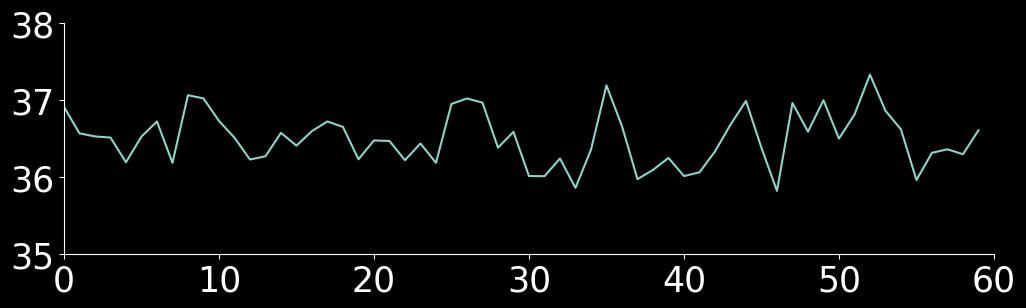

In [48]:
pl.plot(cm.kmeans_init_mt[5][:fs*4])

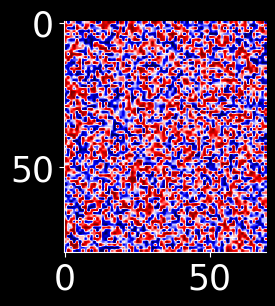

In [49]:
pl.imshow(cm.labels_init.reshape([dx, dy]), interpolation=None)

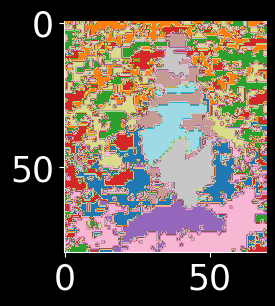

In [53]:
pl.imshow(cm.labels.reshape([dx, dy]), interpolation=None, cmap = 'tab20')